# Synthetic BLS Transit Search

This example injects one periodic transit into a seeded toy light curve and sends it through Albus's Lightkurve-backed `BLSfit`, candidate selection in `BLSResults`, and folding in `FoldedLC`. It saves the periodogram and folded curve under `examples/visuals/`.

The input is synthetic. The recovered period and plots demonstrate the pipeline mechanics only; they are not a planet detection, a survey result, or a completeness estimate. The run searches the period range configured by `BLSfit()` and does not assess a real target.

In [5]:
from pathlib import Path
import os
import sys
import warnings

warnings.simplefilter("ignore")

import lightkurve as lk
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

search_roots = (Path.cwd().resolve(), *Path.cwd().resolve().parents)
repository_root = next(
    candidate for candidate in search_roots
    if (candidate / "BLSFit.py").is_file()
    and (candidate / "paths.py").is_file()
)
if str(repository_root) not in sys.path:
    sys.path.insert(0, str(repository_root))
if str(repository_root.parent.parent / "tansudaylan" / "tdpy") not in sys.path:
    sys.path.insert(0, str(repository_root.parent.parent / "tansudaylan" / "tdpy"))

from BLSFit import BLSfit, BLSResults, FoldedLC
from tdpy.verbosity import print

visuals_directory = repository_root / "examples" / "visuals"
visuals_directory.mkdir(exist_ok=True)
visuals_relative_path = Path(os.path.relpath(visuals_directory, Path.cwd()))
rng = np.random.default_rng(1234)

In [6]:
time_days = np.arange(0.0, 27.0, 0.02)  # [day]
injected_period_days = 3.4  # [day]
injected_epoch_days = 0.7  # [day]
injected_duration_days = 0.034  # [day]
injected_depth = 0.01
noise_standard_deviation = 0.001

phase_days = np.mod(
    time_days - injected_epoch_days + injected_period_days / 2,
    injected_period_days,
) - injected_period_days / 2
in_transit = np.abs(phase_days) < injected_duration_days / 2
flux = 1.0 + rng.normal(0.0, noise_standard_deviation, size=time_days.size)
flux[in_transit] -= injected_depth
light_curve = lk.LightCurve(time=time_days, flux=flux).normalize()

print(
    f"Synthetic points: {time_days.size}; injected period: "
    f"{injected_period_days:.2f} days; transit points: {in_transit.sum()}."
)

Writing to visuals/albus_synthetic_blsplot.png...
Writing to visuals/albus_synthetic_3.4_foldedlc.png...


,injected_period_days,recovered_period_days,fractional_period_error
0,3.4,3.40024,0.00007


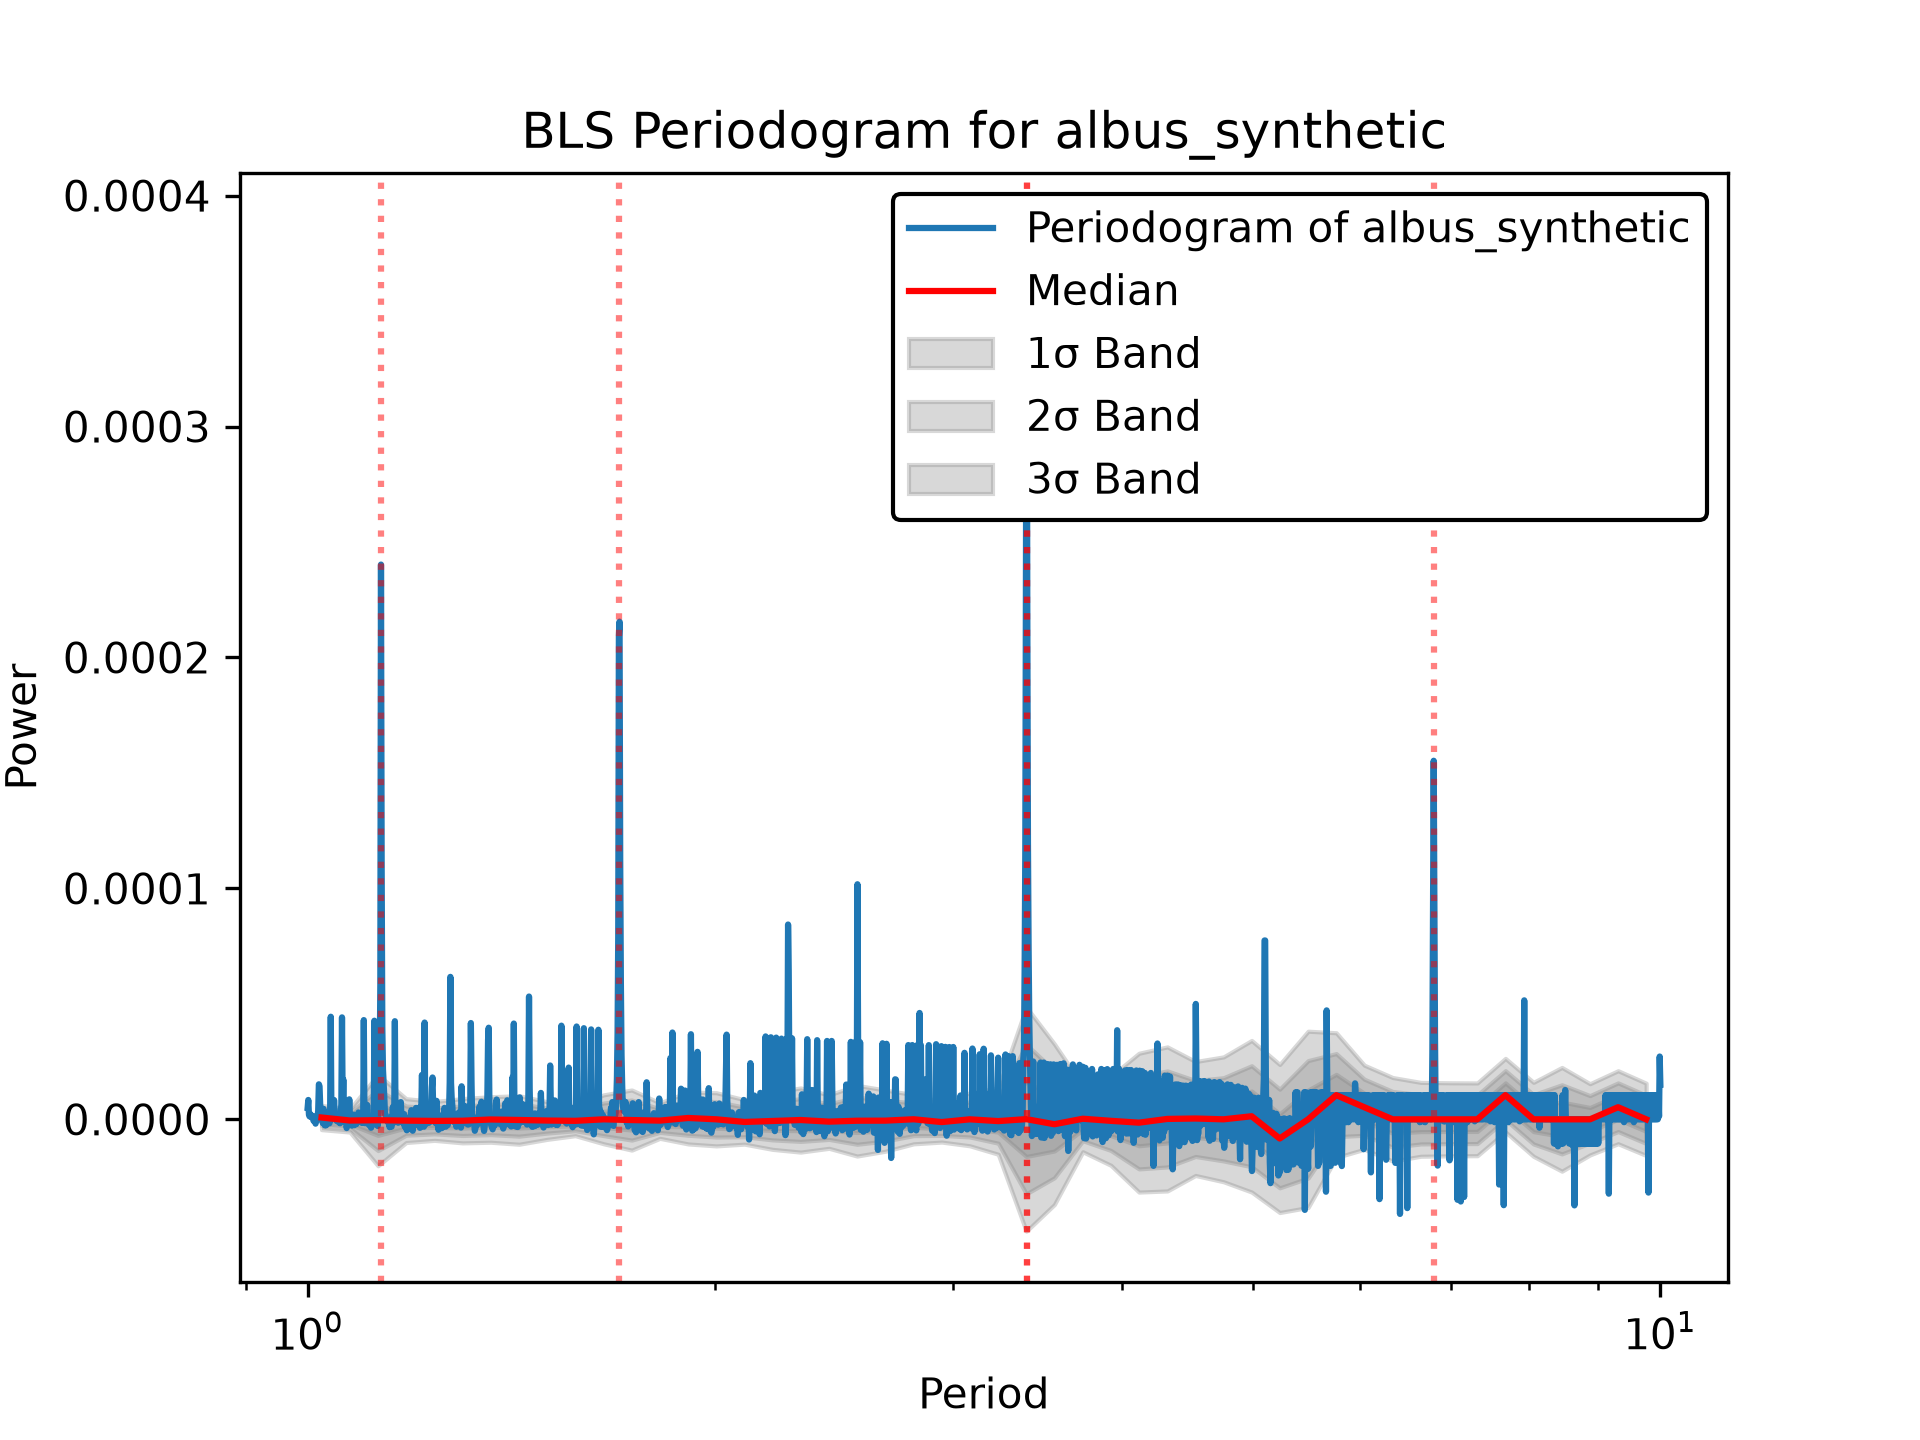

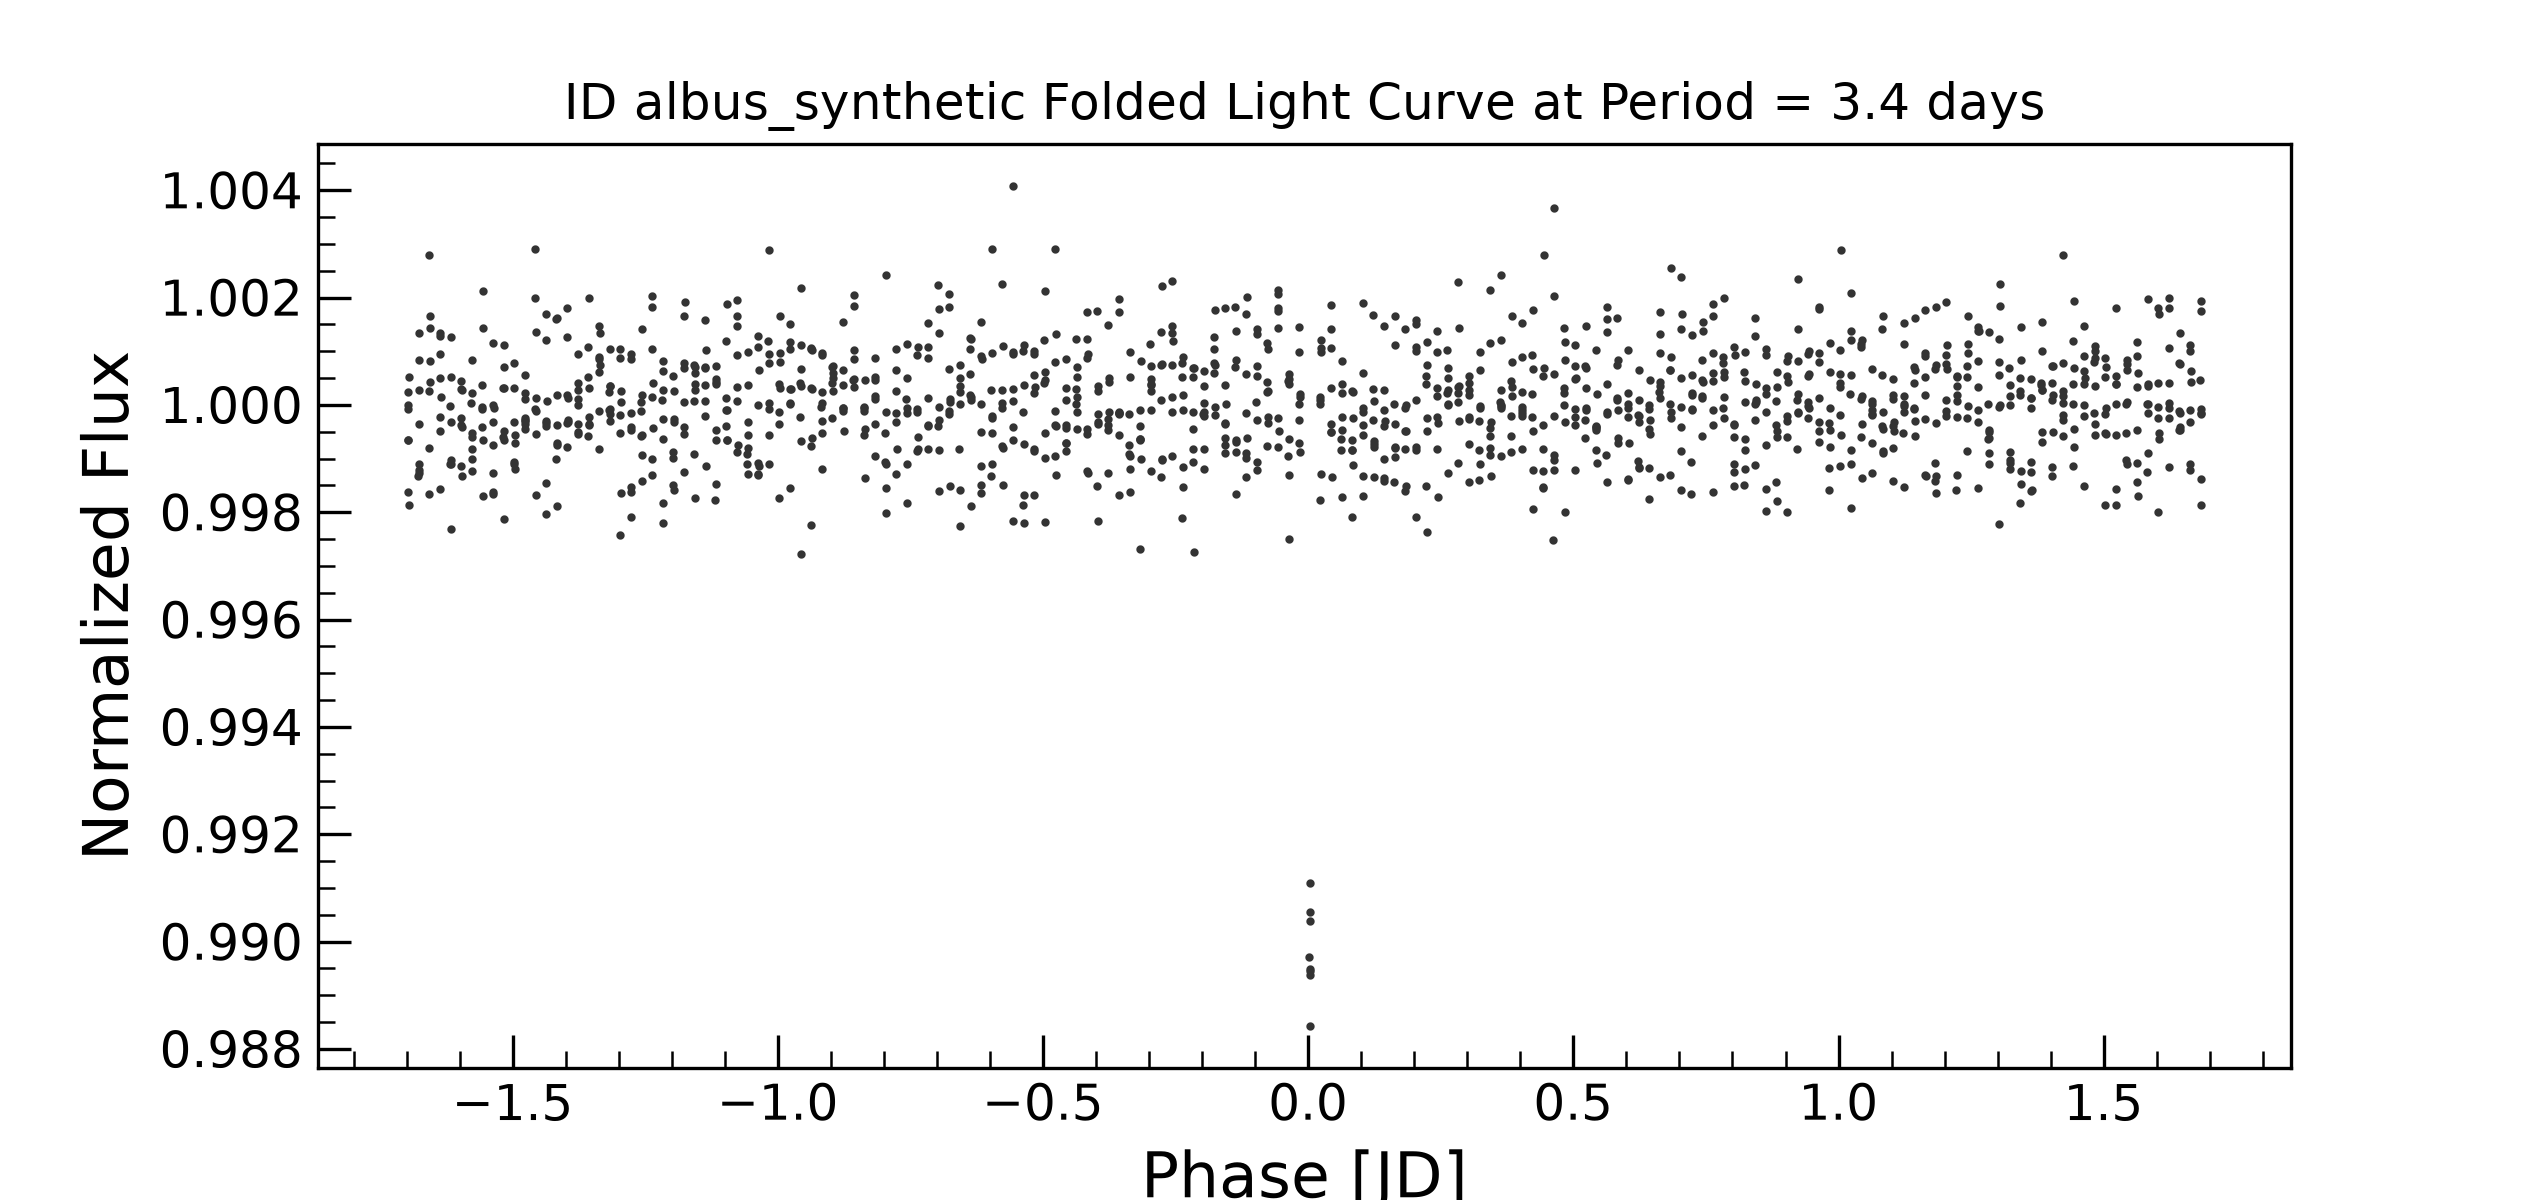

In [7]:
periodogram = BLSfit(light_curve)
high_periods, high_powers, best_period, candidate_epochs, candidate_durations = BLSResults(
    periodogram,
    folder=visuals_relative_path,
    ID="albus_synthetic",
    plot="save",
    candidate_ephemerides=True,
)
folded_curve = FoldedLC(
    light_curve,
    best_period,
    candidate_epochs[0],
    plot="save",
    ID="albus_synthetic",
    folder=visuals_relative_path,
    output=True,
)

recovered_period_days = float(best_period.value)
print(
    f"BLS best period: {recovered_period_days:.2f} days; "
    f"injected period: {injected_period_days:.2f} days."
)
print(f"Distinct candidates returned: {len(high_periods)}.")
period_comparison = pd.DataFrame([{
    "injected_period_days": injected_period_days,
    "recovered_period_days": recovered_period_days,
    "fractional_period_error": abs(recovered_period_days - injected_period_days) / injected_period_days,
}])
display(period_comparison)
display(Image(filename=str(visuals_directory / "albus_synthetic_blsplot.png")))
folded_filename = f"albus_synthetic_{round(recovered_period_days, 3)}_foldedlc.png"
display(Image(filename=str(visuals_directory / folded_filename)))